Name: Christian Aron Vea

GitHub: https://github.com/ChristianAronVea/IND320-Vea

Streamlit: https://ind320-vea-5sc8vxsjg7v4bjgnpamvfl.streamlit.app/

Recording: https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=7db6303f-2cb5-4f02-8134-b4fe010274d6


AI usage and log can be found in separate files in the repo.

In [70]:
import requests
import pandas as pd
from river import time_series, linear_model, preprocessing, optim, metrics
import calendar, math, itertools
import matplotlib.pyplot as plt

### Checking Norweigan bank API

In [32]:
# API for euro and usd from nowegian bank
url_bank = ("https://data.norges-bank.no/api/data/EXR/B.USD+EUR.NOK.SP?endPeriod=2026-11-26&format=sdmx-json&locale=no&startPeriod=2025-11-26")

r = requests.get(url_bank, timeout=10)
print(r.status_code)        # 200 is ok

data_bank = r.json()
print(data_bank.keys())

df_bank = pd.DataFrame(data_bank)
df_bank

200
dict_keys(['meta', 'data'])


,meta,data
id,IREF073301,NaN
prepared,2026-11-26T15:35:39,NaN
test,False,NaN
datasetId,f3d1cd78-3527-4ce3-a9a2-2e387e3e5bce,NaN
sender,{'id': 'Unknown'},NaN
receiver,{'id': 'guest'},NaN
links,"[{'rel': 'self', 'href': '/data/EXR/B.USD+EUR....",NaN
dataSets,NaN,"[{'links': [{'rel': 'dataflow', 'urn': 'urn:sd..."
structure,NaN,"{'links': [{'rel': 'dataflow', 'urn': 'urn:sdm..."


In [ ]:
# Getting the currency rates fron NB
def get_nb_rates(start, end, currencies=("USD", "EUR")):
    """    Start and end has format:  yyyy-mm-dd """
    
    url = (f"https://data.norges-bank.no/api/data/EXR/B.{'+'.join(currencies)}.NOK.SP"
           f"?startPeriod={start}&endPeriod={end}&format=sdmx-json")
    j = requests.get(url, timeout=30).json()["data"]
    dates = [v["id"] for v in j["structure"]["dimensions"]["observation"][0]["values"]]
    base_dim = [d for d in j["structure"]["dimensions"]["series"] if d["id"] == "BASE_CUR"][0]
    rows = []
    for key, s in j["dataSets"][0]["series"].items():
        cur = base_dim["values"][int(key.split(":")[1])]["id"]
        for i, obs in s["observations"].items():
            rows.append((dates[int(i)], cur, float(obs[0])))
    df = pd.DataFrame(rows, columns=["date", "currency", "rate"])
    df["date"] = pd.to_datetime(df["date"])
    return df

In [47]:
# Testing function to retrive NB data
bank_data = get_nb_rates("2026-02-01", "2026-02-04")
bank_data

,date,currency,rate
0,2026-02-02,USD,9.6837
1,2026-02-03,USD,9.6788
2,2026-02-04,USD,9.6442
3,2026-02-02,EUR,11.4655
4,2026-02-03,EUR,11.4220
5,2026-02-04,EUR,11.3995


In [34]:
# Timezones
"""
From searching through previous assignments, I can find that all APIs use the same time zones - local or Europe/Oslo.
"""

'\nFrom searching through previous assignments, I can find that all APIs use the same time zones - local or Europe/Oslo.\n'

### Making River Framework on SARIMAX

In [ ]:
magasinstatistikk = requests.get("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData")

df_mag = pd.DataFrame(magasinstatistikk.json())
df_mag = df_mag.sort_values(by="dato_Id")
df_mag = df_mag[df_mag["omrnr"] == 4]       # choosing region 4
df_mag

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
8285,1995-01-08,EL,4,1995,1,0.542160,21.079208,11.428300,0001-01-01T00:00:00,0.686501,-0.144341
8272,1995-01-15,EL,4,1995,2,0.525037,21.079208,11.067362,0001-01-01T00:00:00,0.542160,-0.017123
8232,1995-01-22,EL,4,1995,3,0.506964,21.079208,10.686392,0001-01-01T00:00:00,0.525037,-0.018073
8162,1995-01-29,EL,4,1995,4,0.486522,21.079208,10.255507,0001-01-01T00:00:00,0.506964,-0.020441
8255,1995-02-05,EL,4,1995,5,0.466650,21.079208,9.836613,0001-01-01T00:00:00,0.486522,-0.019872
...,...,...,...,...,...,...,...,...,...,...,...
8126,2026-10-25,EL,4,2026,43,0.904819,21.079208,19.072859,2026-11-04T13:00:00,0.903060,0.001759
8132,2026-11-01,EL,4,2026,44,0.905202,21.079208,19.080936,2026-11-11T13:00:00,0.904775,0.000427
8303,2026-11-08,EL,4,2026,45,0.920749,21.079208,19.408653,2026-11-18T13:00:00,0.905179,0.015570
8309,2026-11-15,EL,4,2026,46,0.919095,21.079208,19.373804,2026-11-25T13:00:00,0.920709,-0.001614


In [101]:
from river import time_series, metrics

def pred_coming_months_fillings(y, horizon, history, p, d, q):
    """ 
    y: weekly filling series (one region)
    horizon: how many weeks to predict
    history: how many weeks to train on
"""
    # Split: learn on history, but not the horizon
    train = y.iloc[-(horizon + history):-horizon]
    test = y.iloc[-horizon:]

    # Model: same idea as the book's example (p, d, q only)
    model = time_series.SNARIMAX(p, d, q)

    # Learn one value at a time, in time order
    for value in train:
        model.learn_one(value)

    # Forecast the horizon
    forecast = model.forecast(horizon=horizon)

    # Compare with the real values
    mae = metrics.MAE()
    for y_true, y_pred in zip(test, forecast):
        mae.update(y_true, y_pred)
    print(mae)

    # Putting results in a dataframe
    results = pd.DataFrame({
        "date": df_mag["dato_Id"][-horizon:],
        "forecast": forecast,
        "real": test.values
    })

    return results

MAE: 0.302423


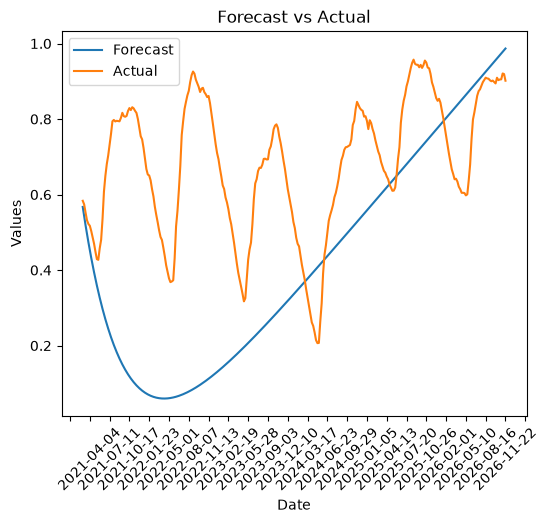

In [128]:
y = df_mag['fyllingsgrad'].dropna()

results = pred_coming_months_fillings(y, 300, 100, 7, 1, 2)

# Plot results
import matplotlib.dates as mdates

plt.figure(figsize=(6, 5))

plt.plot(results["date"], results["forecast"], label="Forecast")
plt.plot(results["date"], results["real"], label="Actual")

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))

plt.xlabel("Date")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.title("Forecast vs Actual")
plt.legend()

plt.show()


In [ ]:
def fill_series(mag, omr_type, omr_nr):
    d = mag[(mag.omrType == omr_type) & (mag.omrnr == omr_nr)].copy()
    # ISO-år + uke -> mandag i den uken
    d["date"] = pd.to_datetime(d.iso_aar.astype(str) + d.iso_uke.astype(str).str.zfill(2) + "1",
                               format="%G%V%u")
    return d.set_index("date")["fyllingsgrad"].sort_index().asfreq("W-MON")


In [ ]:
# --- Features (from the course book, 'month' -> 'date') ---
def get_month_distances(x):
    # RBF-like distance from the current month to each of the 12 months
    return {calendar.month_name[mo]: math.exp(-(x['date'].month - mo) ** 2)
            for mo in range(1, 13)}

def get_ordinal_date(x):
    # Day number since 0001-01-01, acts as a trend feature
    return {'ordinal_date': x['date'].toordinal()}

def build_model(exog_cols=(), p=1, d=0, q=0, m=52, sp=1, sd=0, sq=0,
                lr=0.01, intercept_init=0.0):
    cols = list(exog_cols)

    def get_exog(x):
        # Pick the selected exogenous variables from the input dict
        return {c: x[c] for c in cols}

    features = compose.TransformerUnion(get_ordinal_date, get_month_distances, get_exog)
    return features | time_series.SNARIMAX(
        p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq,
        regressor=preprocessing.StandardScaler() | linear_model.LinearRegression(
            intercept_init=intercept_init,   # as in the book: gives a better start
            optimizer=optim.SGD(lr),
            intercept_lr=0.3))

# --- Future exogenous values: mean per week number from the history ---
def climatology(d_, cols, fidx):
    if not cols:
        return pd.DataFrame(index=fidx)
    wk = d_[cols].groupby(d_.index.isocalendar().week).mean()
    # min(..., 52) guards against ISO week 53, which may be missing in the history
    return pd.DataFrame([wk.loc[min(ts.isocalendar().week, 52)] for ts in fidx], index=fidx)

# --- Main function ---
def forecast_fill(df, target='fylling', exog_cols=(), horizon=12, history=260,
                  x_future=None, **params):
    cols = list(exog_cols)
    # Keep only the last `history` rows and drop NaNs (River needs clean numbers)
    d_ = df[[target] + cols].dropna().iloc[-history:]
    model = build_model(cols, intercept_init=float(d_[target].iloc[0]), **params)

    # Train in chronological order, one observation at a time
    for ts, r in d_.iterrows():
        model.learn_one({'date': ts.date(), **{c: r[c] for c in cols}}, r[target])

    # Future weekly timestamps (Mondays), starting after the last training date
    fidx = pd.date_range(d_.index[-1], periods=horizon + 1, freq='W-MON')[1:]
    if x_future is None:
        x_future = climatology(d_, cols, fidx)
    # One dict per future step, as River's forecast() expects
    xs = [{'date': ts.date(), **{c: x_future.loc[ts, c] for c in cols}} for ts in fidx]
    return pd.Series(model.forecast(horizon=horizon, xs=xs), index=fidx, name='forecast')

# --- Hold-out test, same idea as in the book ---
def backtest(df, target='fylling', exog_cols=(), horizon=12, history=260, **params):
    cols = list(exog_cols)
    # Train on everything except the last `horizon` rows, compare against them
    train, test = df.iloc[:-horizon], df.iloc[-horizon:]
    fc = forecast_fill(train, target, cols, horizon, history,
                       x_future=test[cols],   # actual exogenous values in the test period
                       **params)
    mae, r2 = metrics.MAE(), metrics.R2()
    for yt, yp in zip(test[target], fc):
        mae.update(yt, yp)
        r2.update(yt, yp)
    return fc, mae.get(), r2.get()

In [39]:
# Single run with USD as exogenous variable
fc, mae, r2 = backtest(data, exog_cols=['USD'], horizon=12, p=1, q=0, m=52, sp=1)
print(mae, r2)

# Systematic testing for the report
rows = []
for p, q, hist in itertools.product([1, 2, 3], [0, 1], [104, 260, 520]):
    _, mae, r2 = backtest(data, exog_cols=[], horizon=12, history=hist, p=p, q=q)
    rows.append(dict(p=p, q=q, history=hist, MAE=mae, R2=r2))
pd.DataFrame(rows).sort_values("MAE")

AttributeError: 'dict' object has no attribute 'iloc'